# # Lab 1 - Intro to Behavioral TV Data
# Name: Tymofii | Group: KM-43

## Setup

In [56]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


## Task 1.1 - Panel and universe

In [57]:
telecast_count = programs["telecast_id"].nunique()
programs_count = programs["program_name"].nunique()
networks_count = programs["network_code"].nunique()

weights_hh = daily_weights[daily_weights['resp_type'] == 'H']
weights_p2 = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])]
hh_InPanel = weights_hh['respondent_id'].nunique()
p2_InPanel = weights_p2['respondent_id'].nunique()

hh_intabAVG = weights_hh.groupby('broadcast_date')['resp_type'].count().mean()
p2_intabAVG = weights_p2.groupby('broadcast_date')['resp_type'].count().mean()

us_hh_repres_m = (weights_hh.groupby('broadcast_date')['weight'].sum().mean()) / 1000000
us_p2_repres_m = (weights_p2.groupby('broadcast_date')['weight'].sum().mean()) / 1000000

### Answer:
#### The viewer_attributes table contains all registered respondes, even if they not have any valid(in-tab) measurement days during the current month.


In [58]:
print("Telecasts:", telecast_count)
print("Programs:", programs_count)
print("Networks:", networks_count)
print("Households in panel:", hh_InPanel)
print("Persons in panel:", p2_InPanel)
print("Households in-tab, average day:", hh_intabAVG)
print("Persons in-tab, average day:", p2_intabAVG)
print("US TV households represented, average day (M):", us_hh_repres_m)
print("US persons represented, average day (M):", us_p2_repres_m)

Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878.451612903226
Persons in-tab, average day: 9268.677419354839
US TV households represented, average day (M): 125.80017309677419
US persons represented, average day (M): 317.27768935483874


## Task 1.2 - Average audience by hour of day

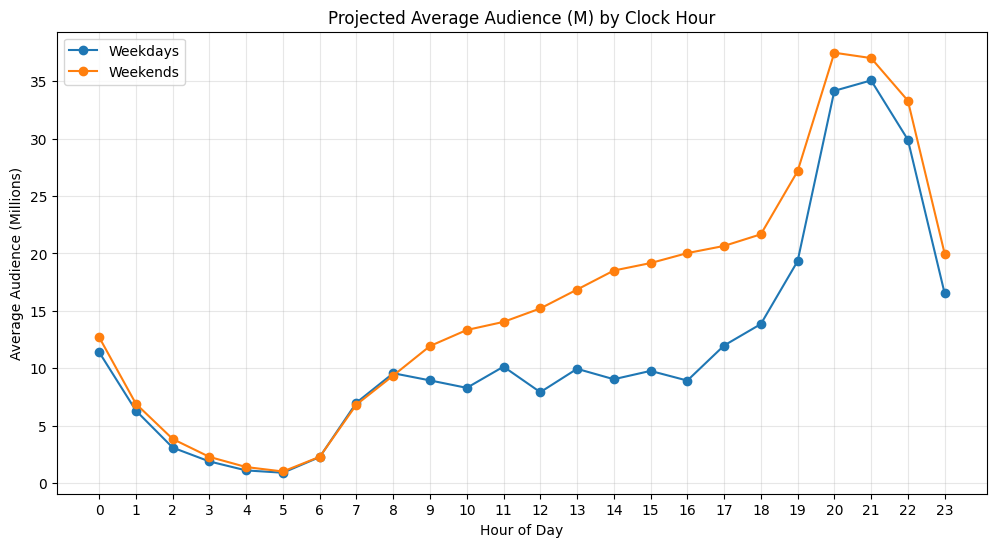

In [59]:
p2_views = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()
p2_views['broadcast_date'] = (p2_views['start_ts'] - pd.Timedelta(hours=6)).dt.date
p2_views['is_weekend'] = pd.to_datetime(p2_views['broadcast_date']).dt.dayofweek >= 5

days_count = p2_views.groupby('is_weekend')['broadcast_date'].nunique()
n_weekdays = days_count.get(False, 0)
n_weekends = days_count.get(True, 0)

records = []
for row in p2_views.itertuples(index=False):
    curr = row.start_ts
    end = row.end_ts
    w = row.weight
    wknd = row.is_weekend

    while curr < end:
        next_hour = curr.ceil('h')
        if next_hour == curr:
            next_hour += pd.Timedelta(hours=1)

        chunk_end = min(end, next_hour)
        mins = (chunk_end - curr).total_seconds() / 60.0

        if mins > 0:
            records.append({
                'hour': curr.hour,
                'weighted_minutes': mins * w,
                'is_weekend': wknd
            })
        curr = chunk_end

hourly_data = pd.DataFrame(records)
hourly_agg = hourly_data.groupby(['is_weekend', 'hour'])['weighted_minutes'].sum().reset_index()

def calc_audience(row):
    days = n_weekends if row['is_weekend'] else n_weekdays
    return (row['weighted_minutes'] / 60 / days) / 1000000

hourly_agg['avg_audience_m'] = hourly_agg.apply(calc_audience, axis=1)

weekdays_df = hourly_agg[~hourly_agg['is_weekend']].sort_values('hour')
weekends_df = hourly_agg[hourly_agg['is_weekend']].sort_values('hour')

plt.figure(figsize=(12, 6))
plt.plot(weekdays_df['hour'], weekdays_df['avg_audience_m'], label='Weekdays', marker='o')
plt.plot(weekends_df['hour'], weekends_df['avg_audience_m'], label='Weekends', marker='o')
plt.title('Projected Average Audience (M) by Clock Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Average Audience (Millions)')
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

peak_weekday = weekdays_df.loc[weekdays_df['avg_audience_m'].idxmax(), 'hour']
peak_weekend = weekends_df.loc[weekends_df['avg_audience_m'].idxmax(), 'hour']

In [60]:
print("Peak hour, weekdays:", int(peak_weekday))
print("Peak hour, weekends:", int(peak_weekend))

Peak hour, weekdays: 21
Peak hour, weekends: 20


### Answer:
#### On weekends there is no sharp morning drop-off and the daytime audience remains higher and more stable compared to weekdays.

## Task 1.3 - Session lenght

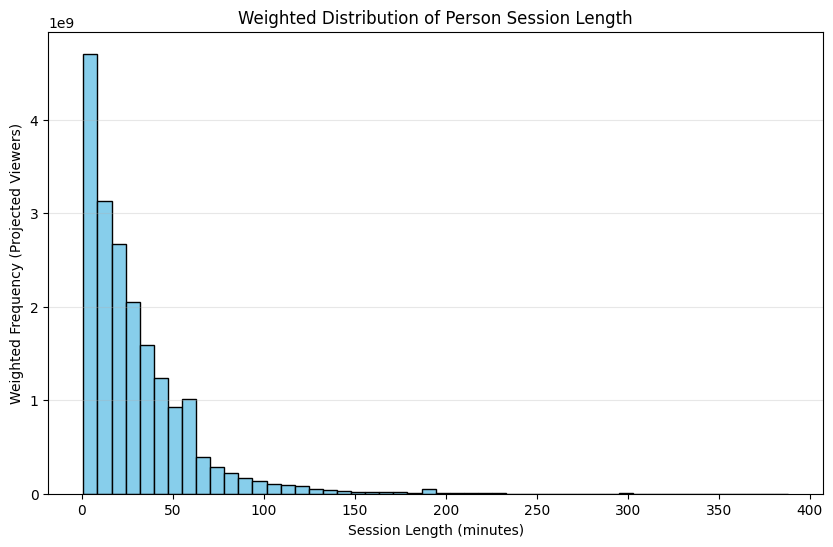

In [61]:
p2_views = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()
p2_views['session_length_min'] = (p2_views['end_ts'] - p2_views['start_ts']).dt.total_seconds() / 60.0
p2_views = p2_views[p2_views['session_length_min'] > 0]

total_weight = p2_views['weight'].sum()
weighted_mean = (p2_views['session_length_min'] * p2_views['weight']).sum() / total_weight

df_sorted = p2_views.sort_values('session_length_min')
df_sorted['cum_weight'] = df_sorted['weight'].cumsum()
cutoff = total_weight / 2.0
weighted_median = df_sorted[df_sorted['cum_weight'] >= cutoff]['session_length_min'].iloc[0]

plt.figure(figsize=(10, 6))
plt.hist(p2_views['session_length_min'], bins=50, weights=p2_views['weight'], color='skyblue', edgecolor='black')
plt.title('Weighted Distribution of Person Session Length')
plt.xlabel('Session Length (minutes)')
plt.ylabel('Weighted Frequency (Projected Viewers)')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [62]:
print("Session length, weighted mean (min):", round(weighted_mean, 2))
print("Session length, weighted median (min):", round(weighted_median, 2))

Session length, weighted mean (min): 29.37
Session length, weighted median (min): 21.0


### Answer:
#### The mean is significantly higher than the median because the distribution of session durations is heavily right-skewed. Most people watch television in short sessions, but a small number of viewers leave the TV on all day, and these "outliers" pull the arithmetic mean sharply upward. It is better to show the median in the client presentation, as it more accurately reflects the behavior of a typical, "normal" viewer.

## Task 2 - Program reach curve

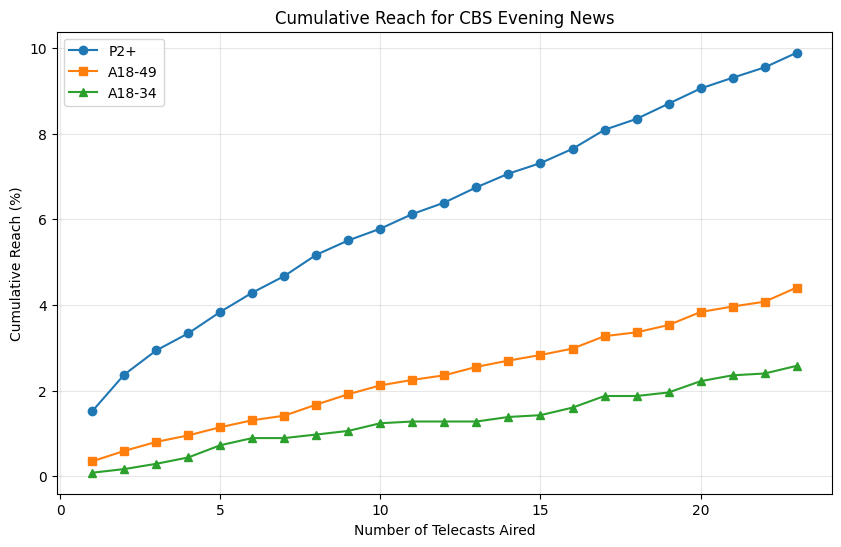

In [65]:
cbs_news = programs[(programs['program_name'] == 'CBS Evening News') &
                    (programs['network_code'] == 'CBS')].sort_values('start_ts').copy()

daily_univ_h = daily_weights[daily_weights['resp_type'] == 'H'].groupby('broadcast_date')['weight'].sum()
daily_univ_p2 = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])].groupby('broadcast_date')['weight'].sum()

ages = viewer_attributes[viewer_attributes['attr_id'] == 300][['respondent_id', 'value']].rename(columns={'value': 'age'})

df_persons = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])].copy()
monthly_weights = df_persons.groupby('respondent_id')['weight'].mean().reset_index()
monthly_weights = monthly_weights.merge(ages, on='respondent_id', how='left')

univ_reach_p2 = monthly_weights['weight'].sum()
univ_reach_a18_34 = monthly_weights[(monthly_weights['age'] >= 18) & (monthly_weights['age'] <= 34)]['weight'].sum()
univ_reach_a18_49 = monthly_weights[(monthly_weights['age'] >= 18) & (monthly_weights['age'] <= 49)]['weight'].sum()

cbs_views = viewings[(viewings['network_code'] == 'CBS') & (viewings['resp_type'] != 'S')].copy()
valid_viewers_list = []

for _, tel in cbs_news.iterrows():
    t_id = tel['telecast_id']
    t_start = tel['start_ts']
    t_end = tel['end_ts']
    b_date = tel['broadcast_date']

    overlaps = cbs_views[(cbs_views['start_ts'] < t_end) & (cbs_views['end_ts'] > t_start)].copy()

    if not overlaps.empty:
        overlaps['adj_start'] = overlaps['start_ts'].clip(lower=t_start)
        overlaps['adj_end'] = overlaps['end_ts'].clip(upper=t_end)
        overlaps['watched_min'] = (overlaps['adj_end'] - overlaps['adj_start']).dt.total_seconds() / 60.0

        viewer_mins = overlaps.groupby(['respondent_id', 'resp_type'])['watched_min'].sum().reset_index()

        valid_resps = viewer_mins[viewer_mins['watched_min'] >= 1.0].copy()

        if not valid_resps.empty:
            valid_resps['telecast_id'] = t_id
            valid_resps['broadcast_date'] = b_date
            valid_viewers_list.append(valid_resps)

if valid_viewers_list:
    all_telecast_viewers = pd.concat(valid_viewers_list, ignore_index=True)
else:
    all_telecast_viewers = pd.DataFrame(columns=['respondent_id', 'resp_type', 'watched_min', 'telecast_id', 'broadcast_date'])

all_telecast_viewers = all_telecast_viewers.merge(
    daily_weights[['respondent_id', 'broadcast_date', 'weight']],
    on=['respondent_id', 'broadcast_date'],
    how='left'
)

all_telecast_viewers = all_telecast_viewers.merge(ages, on='respondent_id', how='left')

ratings_data = []
reach_data = []

seen_p2 = set()
seen_a18_34 = set()
seen_a18_49 = set()

for t_id in cbs_news['telecast_id']:
    t_viewers = all_telecast_viewers[all_telecast_viewers['telecast_id'] == t_id]
    b_date = cbs_news[cbs_news['telecast_id'] == t_id]['broadcast_date'].iloc[0]

    hh_w = t_viewers[t_viewers['resp_type'] == 'H']['weight'].sum()
    p2_w = t_viewers[t_viewers['resp_type'].isin(['R', 'L'])]['weight'].sum()

    hh_rating = (hh_w / daily_univ_h.get(b_date, 1)) * 100
    p2_rating = (p2_w / daily_univ_p2.get(b_date, 1)) * 100
    proj_aud_m = p2_w / 1_000_000

    ratings_data.append({
        'telecast_id': t_id,
        'HH_Rating': hh_rating,
        'P2_Rating': p2_rating,
        'Projected_Audience_M': proj_aud_m
    })

    p2_viewers = t_viewers[t_viewers['resp_type'].isin(['R', 'L'])]

    seen_p2.update(p2_viewers['respondent_id'])
    seen_a18_34.update(p2_viewers[(p2_viewers['age'] >= 18) & (p2_viewers['age'] <= 34)]['respondent_id'])
    seen_a18_49.update(p2_viewers[(p2_viewers['age'] >= 18) & (p2_viewers['age'] <= 49)]['respondent_id'])

    reach_p2_w = monthly_weights[monthly_weights['respondent_id'].isin(seen_p2)]['weight'].sum()
    reach_a18_34_w = monthly_weights[monthly_weights['respondent_id'].isin(seen_a18_34)]['weight'].sum()
    reach_a18_49_w = monthly_weights[monthly_weights['respondent_id'].isin(seen_a18_49)]['weight'].sum()

    reach_data.append({
        'telecast_id': t_id,
        'Reach_P2+': (reach_p2_w / univ_reach_p2) * 100 if univ_reach_p2 else 0,
        'Reach_A18-34': (reach_a18_34_w / univ_reach_a18_34) * 100 if univ_reach_a18_34 else 0,
        'Reach_A18-49': (reach_a18_49_w / univ_reach_a18_49) * 100 if univ_reach_a18_49 else 0
    })

ratings_df = pd.DataFrame(ratings_data)
reach_df = pd.DataFrame(reach_data)

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(reach_df) + 1), reach_df['Reach_P2+'], label='P2+', marker='o')
plt.plot(range(1, len(reach_df) + 1), reach_df['Reach_A18-49'], label='A18-49', marker='s')
plt.plot(range(1, len(reach_df) + 1), reach_df['Reach_A18-34'], label='A18-34', marker='^')

plt.title('Cumulative Reach for CBS Evening News')
plt.xlabel('Number of Telecasts Aired')
plt.ylabel('Cumulative Reach (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [66]:
print("Telecasts of the program:", len(cbs_news))
print("Average household rating (%):", round(ratings_df['HH_Rating'].mean(), 1))
print("Average P2+ rating (%):", round(ratings_df['P2_Rating'].mean(), 1))
print("Average projected audience (M):", round(ratings_df['Projected_Audience_M'].mean(), 2))
print("Final reach P2+ (%):", round(reach_df['Reach_P2+'].iloc[-1], 1))
print("Final reach A18-34 (%):", round(reach_df['Reach_A18-34'].iloc[-1], 1))
print("Final reach A18-49 (%):", round(reach_df['Reach_A18-49'].iloc[-1], 1))

Telecasts of the program: 23
Average household rating (%): 3.2
Average P2+ rating (%): 1.6
Average projected audience (M): 4.93
Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4


### Answer:
#### Cumulative reach steadily increases as new, unique viewers who did not watch the previous episode join the audience with each new broadcast. At the same time, the rating for each individual broadcast remains stable, as it reflects the audience for that specific transmission only. The program demonstrates the best reach figures among the general audience (p2+) but performs very poorly in younger age groups (18–34 and 18–49); historically, traditional evening news broadcasts on major TV channels tend to attract a predominantly older audience.

## Task 3 - Program frequency

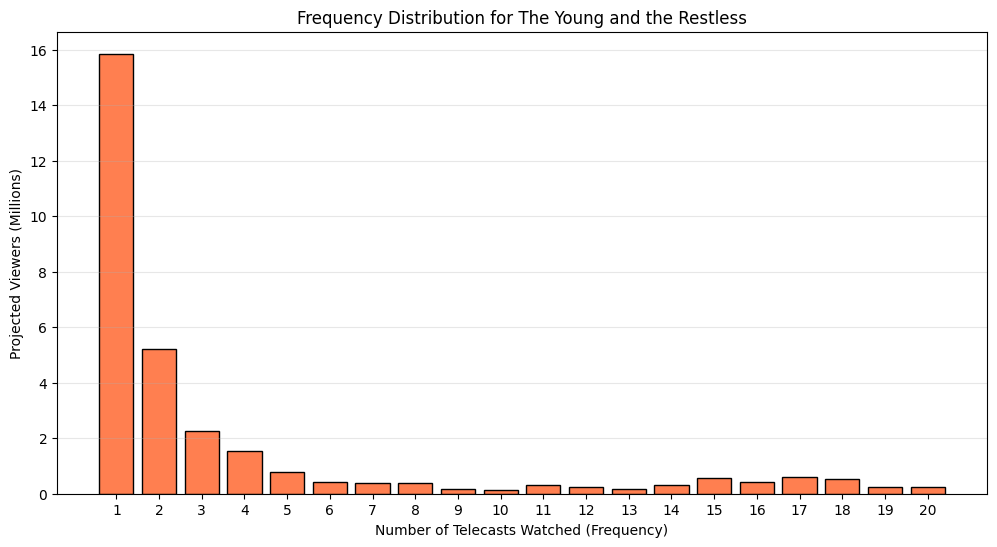

In [67]:
soap_news = programs[(programs['program_name'] == "The Young and the Restless") &
                     (programs['network_code'] == 'CBS')].copy()

df_persons = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])].copy()
monthly_weights = df_persons.groupby('respondent_id')['weight'].mean().reset_index()

cbs_views = viewings[(viewings['network_code'] == 'CBS') & (viewings['resp_type'].isin(['R', 'L']))].copy()
valid_viewers_list = []

for _, tel in soap_news.iterrows():
    t_id = tel['telecast_id']
    t_start = tel['start_ts']
    t_end = tel['end_ts']

    overlaps = cbs_views[(cbs_views['start_ts'] < t_end) & (cbs_views['end_ts'] > t_start)].copy()

    if not overlaps.empty:
        overlaps['adj_start'] = overlaps['start_ts'].clip(lower=t_start)
        overlaps['adj_end'] = overlaps['end_ts'].clip(upper=t_end)
        overlaps['watched_min'] = (overlaps['adj_end'] - overlaps['adj_start']).dt.total_seconds() / 60.0

        viewer_mins = overlaps.groupby('respondent_id')['watched_min'].sum().reset_index()
        valid_resps = viewer_mins[viewer_mins['watched_min'] >= 1.0].copy()

        if not valid_resps.empty:
            valid_resps['telecast_id'] = t_id
            valid_viewers_list.append(valid_resps)

all_soap_views = pd.concat(valid_viewers_list, ignore_index=True)

freq_df = all_soap_views.groupby('respondent_id')['telecast_id'].nunique().reset_index(name='frequency')
freq_df = freq_df.merge(monthly_weights, on='respondent_id', how='left')

proj_viewers_m = freq_df['weight'].sum() / 1_000_000
total_views = (freq_df['frequency'] * freq_df['weight']).sum()
avg_freq = total_views / freq_df['weight'].sum()

freq_sorted = freq_df.sort_values('frequency').copy()
freq_sorted['cum_weight'] = freq_sorted['weight'].cumsum()
total_w = freq_sorted['weight'].sum()

median_freq = freq_sorted[freq_sorted['cum_weight'] >= total_w * 0.5]['frequency'].iloc[0]
p80_freq = freq_sorted[freq_sorted['cum_weight'] >= total_w * 0.8]['frequency'].iloc[0]

loyal_df = freq_df[freq_df['frequency'] >= p80_freq]
loyal_views = (loyal_df['frequency'] * loyal_df['weight']).sum()
loyal_share = (loyal_views / total_views)
dist_df = freq_df.groupby('frequency')['weight'].sum() / 1_000_000

plt.figure(figsize=(12, 6))
plt.bar(dist_df.index, dist_df.values, color='coral', edgecolor='black')
plt.title('Frequency Distribution for The Young and the Restless')
plt.xlabel('Number of Telecasts Watched (Frequency)')
plt.ylabel('Projected Viewers (Millions)')
plt.xticks(range(1, int(dist_df.index.max()) + 1))
plt.grid(axis='y', alpha=0.3)
plt.show()

In [68]:
print("Projected viewers (M):", round(proj_viewers_m, 2))
print("Average frequency (weighted):", round(avg_freq, 2))
print("Median frequency (weighted):", round(median_freq, 2))
print("Share of views from the most loyal viewers:", round(loyal_share, 3))

Projected viewers (M): 30.8
Average frequency (weighted): 3.63
Median frequency (weighted): 1
Share of views from the most loyal viewers: 0.704


## Task 4 - Networks by age and gender

In [69]:
p2_views = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()
p2_views['duration_min'] = (p2_views['end_ts'] - p2_views['start_ts']).dt.total_seconds() / 60.0
p2_views['weighted_min'] = p2_views['duration_min'] * p2_views['weight']

sex_df = viewer_attributes[viewer_attributes['attr_id'].isin([201, 202])][['respondent_id', 'attr_id']].rename(columns={'attr_id': 'sex'})
age_df = viewer_attributes[viewer_attributes['attr_id'] == 300][['respondent_id', 'value']].rename(columns={'value': 'age'})

p2_views = p2_views.merge(sex_df, on='respondent_id', how='left')
p2_views = p2_views.merge(age_df, on='respondent_id', how='left')

def get_demo(row):
    if pd.isna(row['age']) or pd.isna(row['sex']):
        return None

    age = row['age']
    s = 'M' if row['sex'] == 201 else 'W'

    if 18 <= age <= 34: return f'{s}18-34'
    elif 35 <= age <= 54: return f'{s}35-54'
    elif age >= 55: return f'{s}55+'
    return None

p2_views['demo'] = p2_views.apply(get_demo, axis=1)

demos = ['M18-34', 'W18-34', 'M35-54', 'W35-54', 'M55+', 'W55+']
print("--- Top 5 Networks by Projected Minutes (Millions) ---")
for demo in demos:
    df_demo = p2_views[p2_views['demo'] == demo]
    top5 = df_demo.groupby('network_code')['weighted_min'].sum().nlargest(5)

    print(f"\n{demo}:")
    for net, mins in top5.items():
        print(f"  {net}: {mins / 1_000_000:.2f}")

net_total_w = p2_views.groupby('network_code')['weighted_min'].sum()
net_total_raw = p2_views.groupby('network_code')['duration_min'].sum()

views_18_34 = p2_views[(p2_views['age'] >= 18) & (p2_views['age'] <= 34)]
net_18_34_w = views_18_34.groupby('network_code')['weighted_min'].sum()
net_18_34_raw = views_18_34.groupby('network_code')['duration_min'].sum()

share_w = (net_18_34_w / net_total_w).fillna(0)
share_raw = (net_18_34_raw / net_total_raw).fillna(0)
share_df = pd.DataFrame({
    'Weighted_18-34_Share': share_w,
    'Raw_18-34_Share': share_raw
}).sort_values('Weighted_18-34_Share', ascending=False)

print("\n--- 18-34 Share per Network ---")
print(share_df.round(3))

--- Top 5 Networks by Projected Minutes (Millions) ---

M18-34:
  FOX: 4386.65
  NBC: 3910.39
  CBS: 3044.35
  ABC: 3010.78
  FX: 1473.96

W18-34:
  FOX: 4574.44
  NBC: 4527.59
  ABC: 3504.86
  CBS: 2811.22
  FX: 1383.47

M35-54:
  FOX: 12804.67
  NBC: 10986.68
  ABC: 9037.00
  CBS: 8134.07
  FX: 2370.80

W35-54:
  NBC: 11639.10
  FOX: 11161.39
  ABC: 9438.56
  CBS: 8162.80
  HGTV: 3051.81

M55+:
  CBS: 38274.03
  NBC: 34267.41
  FOX: 30878.51
  ABC: 30793.34
  FNC: 27903.71

W55+:
  CBS: 47120.32
  NBC: 41391.87
  ABC: 38840.01
  FOX: 36914.72
  FNC: 31450.73

--- 18-34 Share per Network ---
              Weighted_18-34_Share  Raw_18-34_Share
network_code                                       
FX                           0.266            0.232
BRAVO                        0.148            0.127
FOX                          0.082            0.075
FOOD                         0.078            0.071
NBC                          0.073            0.068
ABC                          0.064  

In [70]:
print("\nYoungest network:", share_w.idxmax())
print("Oldest network:", share_w.idxmin())


Youngest network: FX
Oldest network: FNC


## Answer:
### The "raw" proportion differs from the weighted proportion because the panel's demographic structure does not perfectly match that of the actual U.S. population. If the "raw" share of individuals aged 18–34 is lower than the weighted share, it indicates that this age group is underrepresented in the panel; the system compensates for this by assigning them a higher individual weight. Providing a client with "raw" panel data would create a distorted view of reality by underestimating the size of the youth audience, leading to flawed and financially disadvantageous decisions regarding advertising purchases.